# Credit Scoring - Exploratory Data Analysis

Dataset: "Give Me Some Credit" (Kaggle), 150 000 records.

##  Setup and reading data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/cs-training.csv", index_col=0)
df.shape

(150000, 11)

## Data inspection

In [2]:
summary = pd.DataFrame(
    {
        "dtype": df.dtypes,
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    }
)
summary

,dtype,n_missing,pct_missing,n_unique
SeriousDlqin2yrs,int64,0,0.000,2
RevolvingUtilizationOfUnsecuredLines,float64,0,0.000,125728
age,int64,0,0.000,86
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.000,16
DebtRatio,float64,0,0.000,114194
MonthlyIncome,float64,29731,19.820,13594
NumberOfOpenCreditLinesAndLoans,int64,0,0.000,58
NumberOfTimes90DaysLate,int64,0,0.000,19
NumberRealEstateLoansOrLines,int64,0,0.000,28
NumberOfTime60-89DaysPastDueNotWorse,int64,0,0.000,13


Dataset has 150 000 observations and 11 numeric columns.

Two variables have some missing observations:
- `MonthlyIncome` has significant share of missing values - almost 20%.
- `NumberOfDependents` has almost 3% of missing values.

## Target variable

In [3]:
target = "SeriousDlqin2yrs"
pd.DataFrame(
    {
        "n": df[target].value_counts(),
        "pct": df[target].value_counts(normalize=True).mul(100).round(2),
    }
)

,n,pct
SeriousDlqin2yrs,,
0,139974,93.320
1,10026,6.680


Target variable `SeriousDlqin2yrs` is binary.
The share of positive observations is less than 7%. The classes are not balanced.

## Variables distribution

### Checking the data basic statistics

In [4]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000,150000.000,150000.000,150000.000,150000.000,120269.000,150000.000,150000.000,150000.000,150000.000,146076.000
mean,0.067,6.048,52.295,0.421,353.005,6670.221,8.453,0.266,1.018,0.240,0.757
std,0.250,249.755,14.772,4.193,2037.819,14384.674,5.146,4.169,1.130,4.155,1.115
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.030,41.000,0.000,0.175,3400.000,5.000,0.000,0.000,0.000,0.000
50%,0.000,0.154,52.000,0.000,0.367,5400.000,8.000,0.000,1.000,0.000,0.000
75%,0.000,0.559,63.000,0.000,0.868,8249.000,11.000,0.000,2.000,0.000,1.000
max,1.000,50708.000,109.000,98.000,329664.000,3008750.000,58.000,98.000,54.000,98.000,20.000


### Selected percentiles

In [5]:
num_cols = df.select_dtypes(include="number").columns.drop("SeriousDlqin2yrs")

df[num_cols].quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).T

,0.010,0.250,0.500,0.750,0.950,0.990,0.999
RevolvingUtilizationOfUnsecuredLines,0.000,0.030,0.154,0.559,1.000,1.093,1571.006
age,24.000,41.000,52.000,63.000,78.000,87.000,94.000
NumberOfTime30-59DaysPastDueNotWorse,0.000,0.000,0.000,0.000,2.000,4.000,98.000
DebtRatio,0.000,0.175,0.367,0.868,2449.000,4979.040,10613.074
MonthlyIncome,0.000,3400.000,5400.000,8249.000,14587.600,25000.000,78395.748
NumberOfOpenCreditLinesAndLoans,0.000,5.000,8.000,11.000,18.000,24.000,34.000
NumberOfTimes90DaysLate,0.000,0.000,0.000,0.000,1.000,3.000,98.000
NumberRealEstateLoansOrLines,0.000,0.000,1.000,2.000,3.000,4.000,9.000
NumberOfTime60-89DaysPastDueNotWorse,0.000,0.000,0.000,0.000,1.000,2.000,98.000
NumberOfDependents,0.000,0.000,0.000,1.000,3.000,4.000,6.000


### Boxplots

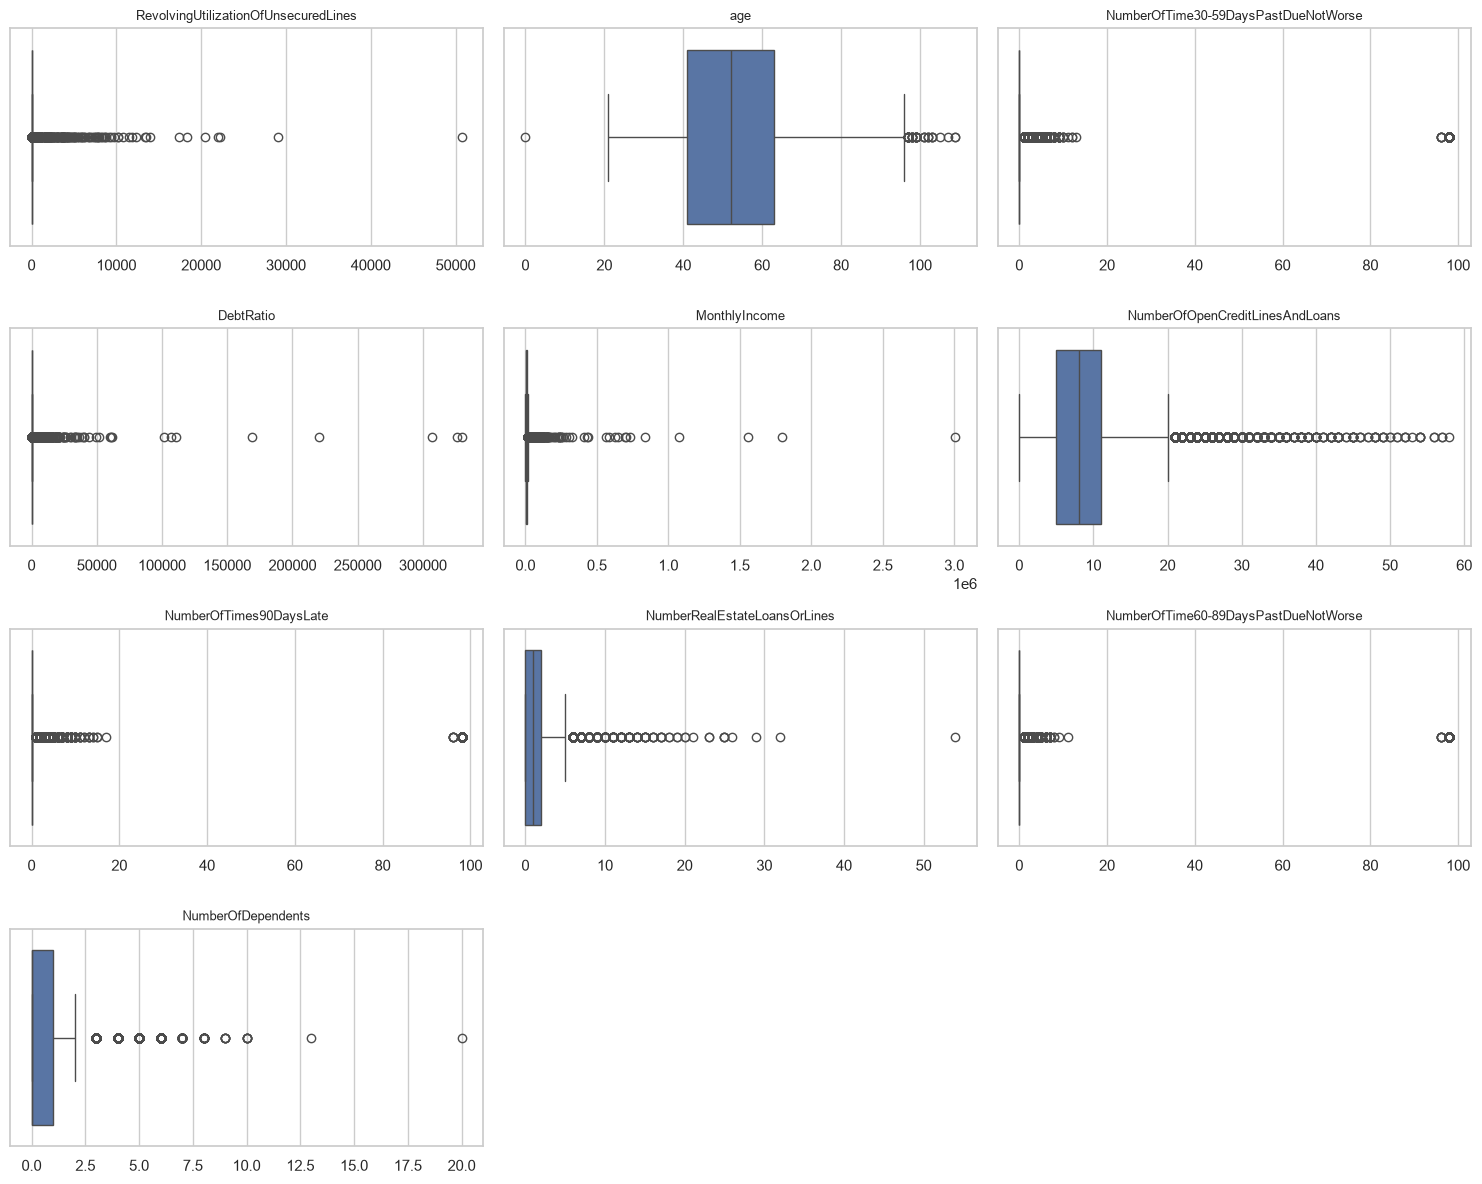

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")

for ax in axes.flat[len(num_cols) :]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Most variables are heavily skewed with extreme values. Following problems are visible:
- The delinquency counters `NumberOfTime30-59DaysPastDueNotWorse`, `NumberOfTime60-89DaysPastDueNotWorse` and `NumberOfTimes90DaysLate` contain a few repeated values around 100.
- `RevolvingUtilizationOfUnsecuredLines` and `DebtRatio` have values exceeding ratio boundaries.
- `Age` includes at least one impossible value.

## Data quality and anomalies

### Age

In [7]:
print("Number of records where Age == 0:", (df["age"] == 0).sum())
print("Number of records where Age < 18:", (df["age"] < 18).sum())
print("Age > 100:", (df["age"] > 100).sum())
print("Maximum Age:", df["age"].max())

Number of records where Age == 0: 1
Number of records where Age < 18: 1
Age > 100: 13
Maximum Age: 109


One observation has impossible `Age` value equal to zero. Several cases are above 100 with maximum value 109. However it is possible in reality.

### Delinquency counters

In [8]:
cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]

mask = (df[cols] > 90).any(axis=1)
df.loc[mask, cols].apply(pd.Series.value_counts).fillna(0).astype(int)

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
98,264,264,264
96,5,5,5


All those cases have values 96/98 in all three columns simultaneously. These values look like special codes.

The outlying values in these three counters are too high to represent real delinquency counts within a two-year window.

In [9]:
print("Number of records with the special code in any column: ", mask.sum())
print(
    "Number of records with the special code in all three columns: ",
    (df[cols] > 90).all(axis=1).sum(),
)

Number of records with the special code in any column:  269
Number of records with the special code in all three columns:  269


Checking the default rate depending on the presence of special codes:

In [10]:
df.groupby(mask)["SeriousDlqin2yrs"].agg(["mean", "count"])

,mean,count
False,0.066,149731
True,0.546,269


Default rate in the group of cases with these special values is much higher than in the other one.

### RevolvingUtilization and DebtRatio

In [11]:
for c in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]:
    print(c)
    print(df[c].quantile([0.5, 0.75, 0.8, 0.9, 0.95, 0.99, 0.999, 1.0]))
    print()

RevolvingUtilizationOfUnsecuredLines
0.500       0.154
0.750       0.559
0.800       0.699
0.900       0.981
0.950       1.000
0.990       1.093
0.999    1571.006
1.000   50708.000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

DebtRatio
0.500        0.367
0.750        0.868
0.800        4.000
0.900     1267.000
0.950     2449.000
0.990     4979.040
0.999    10613.074
1.000   329664.000
Name: DebtRatio, dtype: float64



`RevolvingUtilizationOfUnsecuredLines` - values above 1 are possible (e.g. exceeding the limit or added interest). However values above 99% percentile seem to be some errors - they exceed thousands, which cannot represent a utilization ratio. This happens in about 1% of cases.

`DebtRatio` - while the median is below 0.4, values in the upper part of the distribution reach thousands.

In [12]:
print(f"DebtRatio > 1000: {(df['DebtRatio'] > 1000).mean():.1%}")

print(
    f"DebtRatio > 1 when MonthlyIncome is missing:",
    f"{(df.loc[df['MonthlyIncome'].isna(), 'DebtRatio'] > 1).mean():.1%}",
)

DebtRatio > 1000: 11.3%
DebtRatio > 1 when MonthlyIncome is missing: 93.9%


In over 11% of cases `DebtRatio`is above 1000.

Almost 94% of records with missing income have `DebtRatio` above 1, which confirms that the this variable does not represent the proper ratio for these records.

In [13]:
df.groupby(df["MonthlyIncome"].isna())["DebtRatio"].median()

MonthlyIncome
False      0.296
True    1159.000
Name: DebtRatio, dtype: float64

The median `DebtRatio` is much higher for records without income data.

In [14]:
print("MonthlyIncome == 0:", (df["MonthlyIncome"] == 0).sum())
print(
    "DebtRatio median when income == 0:",
    df.loc[df["MonthlyIncome"] == 0, "DebtRatio"].median(),
)

MonthlyIncome == 0: 1634
DebtRatio median when income == 0: 930.0


Around 1 600 records have `MonthlyIncome` equal to 0 with a median `DebtRatio` of 930 - the same pattern as for missing income. 

## Target relationships

In [15]:
def default_rate_by_bin(df, col, target="SeriousDlqin2yrs", q=10):
    bins = pd.qcut(df[col], q=q, duplicates="drop")
    return df.groupby(bins, observed=True)[target].agg(["mean", "count"])

In this section the default rate tables are shown. For age and income individual thresholds are used for easier interpretation. For utilization and debt ratio there are no obvious cut-off points, so deciles are calculated to keep the groups a similar size.

### Default rate in age groups

In [16]:
age_bins = pd.cut(df["age"], bins=[0, 25, 35, 45, 55, 65, 120])
df.groupby(age_bins, observed=True)["SeriousDlqin2yrs"].agg(["mean", "count"])

,mean,count
age,,
"(0, 25]",0.112,3027
"(25, 35]",0.111,18458
"(35, 45]",0.088,29819
"(45, 55]",0.076,36690
"(55, 65]",0.046,33406
"(65, 120]",0.024,28599


Default rate decreases with age, which is consistent with the expectations.

### Default rate in income groups

In [17]:
income_bins = pd.cut(df["MonthlyIncome"], bins=[0, 3000, 8000, 15000, 30000, 80000])
df.groupby(income_bins, observed=True)["SeriousDlqin2yrs"].agg(["mean", "count"])

,mean,count
MonthlyIncome,,
"(0, 3000]",0.094,23450
"(3000, 8000]",0.073,63734
"(8000, 15000]",0.046,26167
"(15000, 30000]",0.045,4492
"(30000, 80000]",0.056,676


Default rate decreases when monthly income increases excluding the last group with the highest income, when default rate is higher than previous two groups. However this last group is the least numerous.

### Default rate in RevolvingUtilization and DebtRatio


In [18]:
for c in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]:
    print(f"\n{c}")
    display(default_rate_by_bin(df, c))


RevolvingUtilizationOfUnsecuredLines


,mean,count
RevolvingUtilizationOfUnsecuredLines,,
"(-0.001, 0.00297]",0.025,15000
"(0.00297, 0.0192]",0.014,15000
"(0.0192, 0.0435]",0.014,15000
"(0.0435, 0.0832]",0.019,15000
"(0.0832, 0.154]",0.024,15000
"(0.154, 0.271]",0.035,15000
"(0.271, 0.445]",0.052,15000
"(0.445, 0.699]",0.088,15000
"(0.699, 0.981]",0.166,15000



DebtRatio


,mean,count
DebtRatio,,
"(-0.001, 0.0309]",0.054,15000
"(0.0309, 0.134]",0.068,15000
"(0.134, 0.214]",0.060,15000
"(0.214, 0.287]",0.054,15000
"(0.287, 0.367]",0.056,15000
"(0.367, 0.468]",0.067,15000
"(0.468, 0.649]",0.084,15001
"(0.649, 4.0]",0.113,15108
"(4.0, 1267.0]",0.061,14896


In [19]:
print("\nDebtRatio after excluding observations with missing income")
default_rate_by_bin(df[df["MonthlyIncome"].notna()], "DebtRatio")


DebtRatio after excluding observations with missing income


,mean,count
DebtRatio,,
"(-0.001, 0.022]",0.049,12027
"(0.022, 0.108]",0.069,12027
"(0.108, 0.176]",0.063,12027
"(0.176, 0.237]",0.059,12027
"(0.237, 0.296]",0.053,12027
"(0.296, 0.36]",0.055,12026
"(0.36, 0.436]",0.067,12027
"(0.436, 0.543]",0.075,12027
"(0.543, 0.763]",0.097,12027


`RevolvingUtilizationOfUnsecuredLines` - default rate increases monotonically across deciles, from 2.5% in the lowest to 23% in the highest. This relationship is very strong.

`DebtRatio` - on the full dataset the relationship is not monotonic: default rate drops in the top two deciles, which is where records with missing income are present. As shown earlier, the ratio is not meaningful for these records. After excluding them, the relationship is clearer - from the 5th decile the default rate is rising.

### Default rate by delays variables

Observations with special codes 96/98 are excluded from these calculations. The default rate for this group was analyzed in previous sections.

In [20]:
for c in cols:
    print(f"\n{c}")
    display(df.loc[~mask].groupby(c)["SeriousDlqin2yrs"].agg(["mean", "count"]))


NumberOfTime30-59DaysPastDueNotWorse


,mean,count
NumberOfTime30-59DaysPastDueNotWorse,,
0,0.040,126018
1,0.150,16033
2,0.265,4598
3,0.352,1754
4,0.426,747
5,0.450,342
6,0.529,140
7,0.519,54
8,0.320,25



NumberOfTime60-89DaysPastDueNotWorse


,mean,count
NumberOfTime60-89DaysPastDueNotWorse,,
0,0.051,142396
1,0.310,5731
2,0.502,1118
3,0.566,318
4,0.619,105
5,0.618,34
6,0.750,16
7,0.556,9
8,0.500,2



NumberOfTimes90DaysLate


,mean,count
NumberOfTimes90DaysLate,,
0,0.046,141662
1,0.337,5243
2,0.499,1555
3,0.577,667
4,0.670,291
5,0.634,131
6,0.600,80
7,0.816,38
8,0.714,21


Default rate increases sharply with the number of times past due. The growth is monotonic up to 6 occurrences for `NumberOfTime30-59DaysPastDueNotWorse` and up to 4 for the other two variables. Beyond that it becomes unstable, but these groups contain very few observations, so the estimates are not reliable.

The effect is strongest for `NumberOfTimes90DaysLate` - the default rate increases from 4.6% with no delinquencies to 33.7% after a single event.

### Density plots by target group

Kernel density plots are shown for continuous variables without extreme outliers. For the remaining features the default rate tables are more informative.

Note that the income axis is truncated at the 99th percentile for readability, and records with missing income are excluded from the plot.

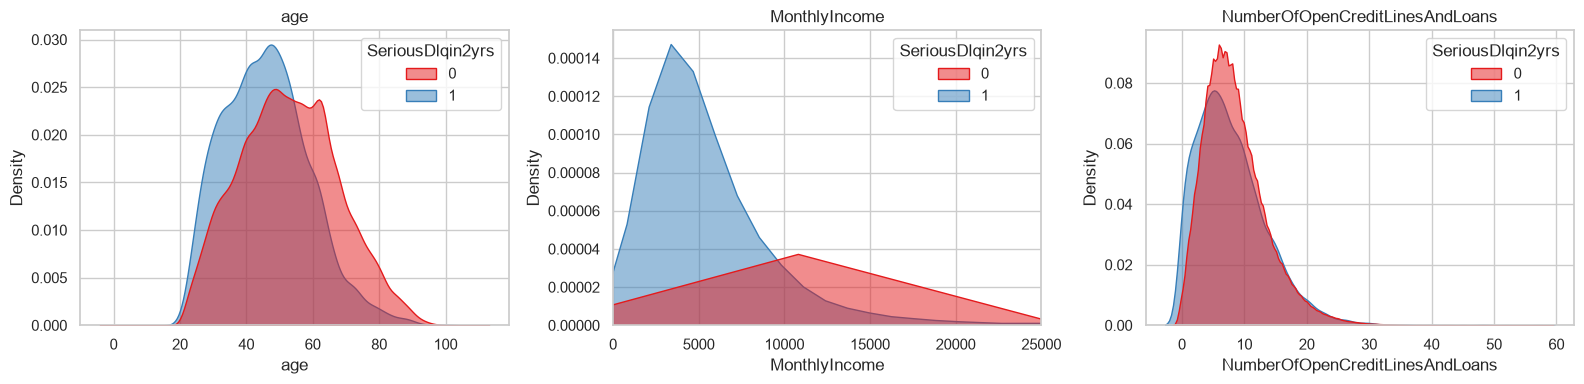

In [21]:
variables = ["age", "MonthlyIncome", "NumberOfOpenCreditLinesAndLoans"]
target_col = "SeriousDlqin2yrs"

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, variables):
    sns.kdeplot(
        data=df,
        x=col,
        hue=target_col,
        fill=True,
        common_norm=False,
        palette="Set1",
        alpha=0.5,
        ax=ax,
    )
    ax.set_title(col)
    if col == "MonthlyIncome":
        ax.set_xlim(0, df[col].quantile(0.99))

plt.tight_layout()
plt.show()

Above plots confirm the patterns visible in the default rate tables: defaults are concentrated in lower income ranges and in the 30-50 age group, while `NumberOfOpenCreditLinesAndLoans` shows similar distributions for both classes, indicating weak discriminatory power.

## Correlations

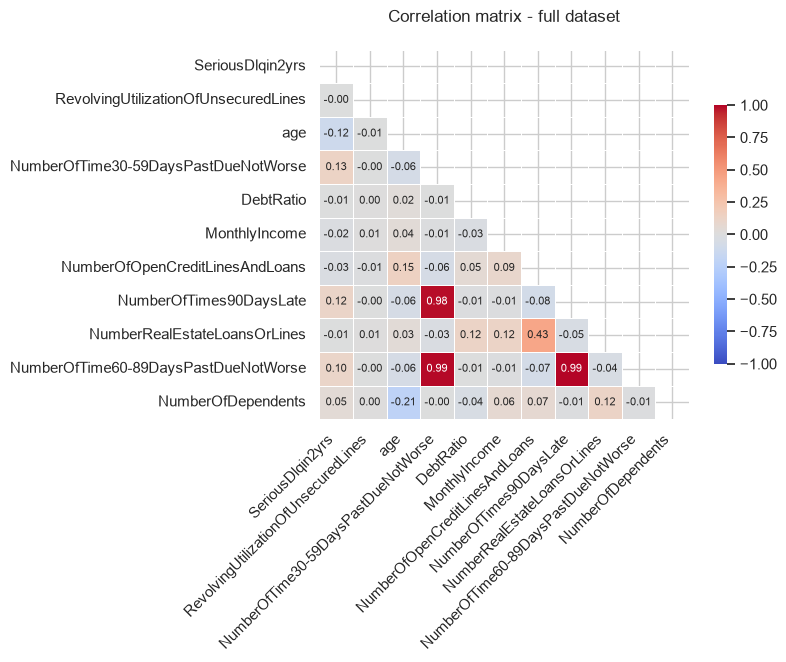

In [22]:
corr_matrix = df.corr()
mask_upper = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask_upper,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    annot_kws={"size": 8},
    cbar_kws={"shrink": 0.7},
)
plt.xticks(rotation=45, ha="right")
plt.title("Correlation matrix - full dataset", pad=20)
plt.show()

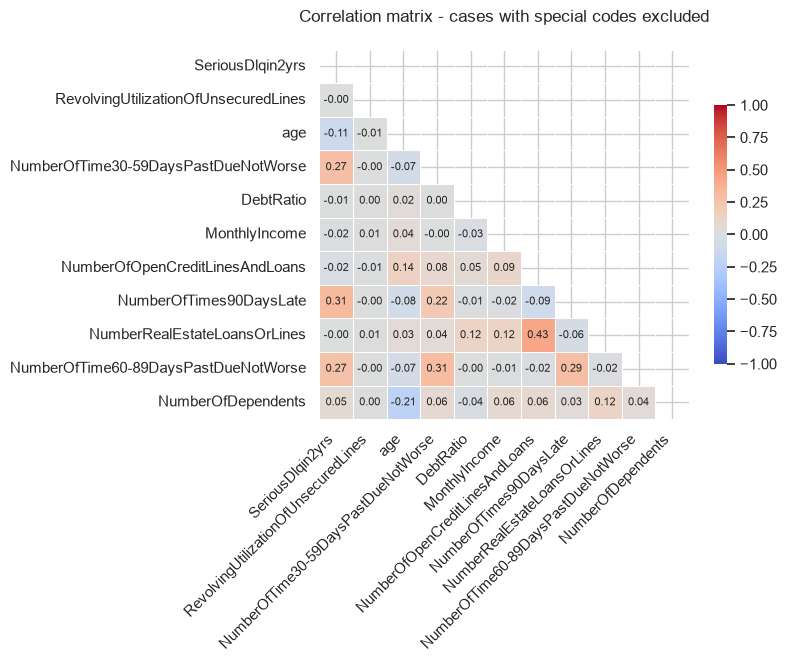

In [23]:
corr_matrix = df.loc[~mask].corr()
mask_upper = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask_upper,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    annot_kws={"size": 8},
    cbar_kws={"shrink": 0.7},
)
plt.xticks(rotation=45, ha="right")
plt.title("Correlation matrix - cases with special codes excluded", pad=20)
plt.show()

- Variables `NumberOfTime30-59DaysPastDueNotWorse`, `NumberOfTime60-89DaysPastDueNotWorse` and `NumberOfTimes90DaysLate` look almost perfectly correlated (0.98-0.99) on the full dataset.
- After removing records with special codes, the correlations drop to 0.22-0.31. So the high values were caused by those codes appearing in all three columns at the same time.
- At the same time correlation of those variables with the target has increased from 0.10-0.13 to 0.27-0.31. The special codes were hiding how strongly these variables are related to default. 
- `NumberOfRealEstateLoansOrLines` and `NumberOfOpenCreditLinesAndLoans` are moderately correlated (0.43). This makes sense, as both count credit products.
- `RevolvingUtilizationOfUnsecuredLines` shows no correlation with the target, but the decile analysis showed a strong relationship. Correlation does not capture it because the variable is highly skewed with extreme values.


## Conclusions and decisions for further steps
- `age = 0` - one record which seems to be data error. It will be removed.
- `MonthlyIncome` (around 20% missing) - missing values will be imputed with the median. An additional flag `income_missing` will be added. Zero values are kept, as they are possible. 
- `NumberOfDependents` (2.6% missing) - will be imputed with median.
- Special codes 96/98 are replaced with -1 to mark them as outside the normal range of the variable rather than as a real count. A flag `special_status` will be added, since the default rate in this group is much higher than in the rest of the data.
- `DebtRatio` - for records with missing or zero income the value is not a ratio and will be treated as missing. For the remaining records the variable will be capped at the 99th percentile.
- `RevolvingUtilizationOfUnsecuredLines` - extreme values will be capped at the 99th percentile. Values above 1 are possible and will be kept.
- Delinquency counters - will be capped based on the group sizes and the stability of defaults rates: at 6 for `NumberOfTime30-59DaysPastDueNotWorse`, and at 4 for the other two. Above these values the number of records drops below 100 and the default rate becomes unstable.
- Due to the imbalanced target (around 7% defaults):
    - Accuracy will not be a useful metric. ROC-AUC (or Gini) will be used instead.
    - Train-test split and cross-validation will be stratified.
    - Class weighting will be tested during modelling.